# Reproducing "On Calibration of Modern Neural Networks" (Guo et al., 2017)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Utkarsh5832/calibration-reproduction/blob/main/calibration_reproduction.ipynb)

**Author:** Utkarsh Alagh, B.Tech Electrical Engineering, IIT Delhi

**Paper:** C. Guo, G. Pleiss, Y. Sun, K. Q. Weinberger. *On Calibration of Modern Neural Networks.* ICML 2017. [arXiv:1706.04599](https://arxiv.org/abs/1706.04599)

## Summary

A classifier outputs a prediction together with a confidence, for example "cat, 90% sure". The model is *calibrated* if, among all predictions made with 90% confidence, about 90% are correct. Guo et al. show that modern deep networks are often **overconfident** (they claim more confidence than their accuracy justifies) and that a one-parameter post-processing step, **temperature scaling**, largely repairs this without changing which class is predicted.

This notebook does two things:

1. **Reproduction.** Train ResNet-18 on CIFAR-10 (3 random seeds), measure miscalibration with the Expected Calibration Error (ECE) and reliability diagrams, and apply temperature scaling.
2. **Extension.** Ask a question the paper's main experiments do not: *if the temperature is fitted on clean images, does it still give calibrated confidences when the test images are corrupted (Gaussian noise, Gaussian blur)?*

### Main results (ResNet-18, CIFAR-10, mean ± std over 3 training seeds)

| | test accuracy | ECE | NLL |
|---|---|---|---|
| uncalibrated | 92.97 ± 0.11 % | 3.13 ± 0.13 % | 0.241 ± 0.006 |
| temperature scaled | 92.97 ± 0.11 % | 0.75 ± 0.14 % | 0.214 ± 0.003 |

The fitted temperature was T = 1.47, 1.50 and 1.47 for the three seeds (T > 1 means the raw network was overconfident). Accuracy is identical before and after scaling, as the method guarantees.

### Extension finding

A temperature fitted on clean validation images keeps ECE at about 0.7 to 1.4 % while the test images are only mildly corrupted (accuracy within about 4 points of clean). As the corruption grows and accuracy falls, the benefit shrinks sharply: for example at noise std 0.05 (accuracy 68.9 %) ECE only falls from 18.7 % to 12.0 %, and at blur sigma 1.0 (accuracy 32.7 %) from 49.7 % to 40.4 %. A single scalar fitted on in-distribution data cannot account for a shift in the inputs.

The numbers above come from the cells below, run on saved models and outputs (see "Reproducibility").

## Contents

1. Background: calibration, ECE, temperature scaling
2. Experimental protocol
3. Setup
4. Data, model and training
5. Calibration metrics (with a hand-checked test)
6. Reproduction results
7. Extension: calibration under distribution shift
8. Comparison with the paper
9. Limitations and next steps
10. Reproducibility and references

## 1. Background

**Calibration.** Let $\hat{Y}$ be the predicted class and $\hat{P}$ the model's confidence (the largest softmax probability). The model is *perfectly calibrated* if

$$\mathbb{P}(\hat{Y} = Y \mid \hat{P} = p) = p \quad \forall p \in [0,1].$$

**Estimating it from data.** Because $\hat{P}$ is continuous, predictions are grouped into $M$ equal-width confidence bins $B_1, \dots, B_M$, and in each bin the accuracy and the average confidence are compared:

$$\mathrm{acc}(B_m) = \frac{1}{|B_m|}\sum_{i \in B_m} \mathbf{1}(\hat{y}_i = y_i), \qquad \mathrm{conf}(B_m) = \frac{1}{|B_m|}\sum_{i \in B_m} \hat{p}_i .$$

A **reliability diagram** plots $\mathrm{acc}(B_m)$ against confidence. A perfectly calibrated model lies on the diagonal, and bars below the diagonal indicate overconfidence.

**Expected Calibration Error (ECE)** is the bin-size-weighted average gap, with $n$ the number of samples:

$$\mathrm{ECE} = \sum_{m=1}^{M} \frac{|B_m|}{n}\,\bigl|\mathrm{acc}(B_m) - \mathrm{conf}(B_m)\bigr| .$$

**Maximum Calibration Error (MCE)** is the single largest bin gap, $\max_m |\mathrm{acc}(B_m) - \mathrm{conf}(B_m)|$.

**Negative log-likelihood (NLL)** is the usual cross-entropy loss, $-\frac{1}{n}\sum_i \log \hat{\pi}(y_i \mid x_i)$, reported here as a second metric.

**Temperature scaling.** Given the logits $z$ of a trained network, replace the softmax by $\mathrm{softmax}(z / T)$ with one scalar $T > 0$ chosen to minimise NLL on a held-out **validation** set. Dividing all logits by the same positive number never changes which class has the largest logit, so **accuracy is unchanged**. For $T > 1$ the output probabilities become less extreme.

## 2. Experimental protocol

These choices follow the paper's setup for CIFAR where it is specified, and are stated explicitly so the results can be checked.

- **Data split.** The 50,000 CIFAR-10 training images are split once (fixed seed) into 45,000 for training and 5,000 for validation. The 10,000 official test images are used only for reporting. This matches the 45,000 / 5,000 / 10,000 split in the paper.
- **Model.** ResNet-18 from `torchvision`, with the first convolution replaced by a 3x3 stride-1 convolution and the max-pool removed (the standard stem is designed for much larger images).
- **Training.** SGD with momentum 0.9, learning rate 0.1 with cosine decay, weight decay 5e-4, batch size 128, 30 epochs, random crop (padding 4) and horizontal flip augmentation.
- **Seeds.** Three independent training runs (seeds 0, 1, 2). The seed changes the initial weights and the data order. The train/validation split is the same for all seeds.
- **Calibration metrics.** ECE and MCE with $M = 15$ equal-width bins (as in the paper), and NLL.
- **Temperature.** Fitted separately for each seed, by minimising NLL on that seed's 5,000 validation images with a grid search over $T \in [0.5, 3.0)$ in steps of 0.01. The test set is never used to fit $T$.
- **Extension.** Test images are corrupted before normalisation (pixel values in $[0,1]$) with Gaussian noise of standard deviation $s$, or Gaussian blur with standard deviation $\sigma$ (7x7 kernel). The temperature fitted on **clean** validation images is applied unchanged.

## 3. Setup

Runs in Google Colab (a GPU is only needed for retraining or for recomputing the extension). Saved models and outputs live in a Google Drive folder, `calib_project`. Set `TRAIN = True` to retrain the models from scratch.

In [3]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader, Subset

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJ = '/content/drive/MyDrive/calib_project'
except ImportError:                      # running somewhere other than Colab
    PROJ = './calib_project'
os.makedirs(PROJ, exist_ok=True)
FIG = f'{PROJ}/figures'
os.makedirs(FIG, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

SEEDS = [0, 1, 2]
N_BINS = 15
EPOCHS = 30
TRAIN = False        # True: retrain all models (about 20-25 min per seed on a free Colab GPU)

Mounted at /content/drive
device: cuda


## 4. Data, model and training

The training function saves, for each seed, the model weights and the **logits** (raw network outputs) for the validation and test sets. Everything in the later sections is computed from these saved files, so no retraining is needed to reproduce the tables and figures.

In [4]:
NORM_MEAN, NORM_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

def make_model():
    m = torchvision.models.resnet18(num_classes=10)
    m.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)    # 3x3 stride 1 for 32x32 images
    m.maxpool = nn.Identity()
    return m.to(device)

def get_logits(model, loader):
    model.eval()
    outs, ys = [], []
    with torch.no_grad():
        for x, y in loader:
            outs.append(model(x.to(device)).cpu())
            ys.append(y)
    return torch.cat(outs), torch.cat(ys)

def build_loaders():
    train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                          T.ToTensor(), T.Normalize(NORM_MEAN, NORM_STD)])
    eval_tf = T.Compose([T.ToTensor(), T.Normalize(NORM_MEAN, NORM_STD)])
    full_train = torchvision.datasets.CIFAR10(f'{PROJ}/data', train=True, download=True, transform=train_tf)
    full_val   = torchvision.datasets.CIFAR10(f'{PROJ}/data', train=True, download=True, transform=eval_tf)
    test_set   = torchvision.datasets.CIFAR10(f'{PROJ}/data', train=False, download=True, transform=eval_tf)
    perm = torch.randperm(50000, generator=torch.Generator().manual_seed(0)).tolist()   # fixed 45k / 5k split
    return (DataLoader(Subset(full_train, perm[:45000]), batch_size=128, shuffle=True, num_workers=2),
            DataLoader(Subset(full_val,   perm[45000:]), batch_size=256),
            DataLoader(test_set, batch_size=256))

def train_seed(seed, loaders, epochs=EPOCHS):
    train_loader, val_loader, test_loader = loaders
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    model = make_model()
    criterion = nn.CrossEntropyLoss()
    opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            opt.step()
        sched.step()
        print(f'seed {seed} | epoch {epoch+1}/{epochs} | last batch loss {loss.item():.3f}')
    vl, vy = get_logits(model, val_loader)
    tl, ty = get_logits(model, test_loader)
    torch.save(model.state_dict(), f'{PROJ}/resnet18_seed{seed}.pt')
    torch.save({'val_logits': vl, 'val_labels': vy, 'test_logits': tl, 'test_labels': ty},
               f'{PROJ}/logits_seed{seed}.pt')
    return (tl.argmax(1) == ty).float().mean().item()

if TRAIN:
    loaders = build_loaders()
    for seed in SEEDS:
        if os.path.exists(f'{PROJ}/logits_seed{seed}.pt'):
            print(f'seed {seed}: already trained, skipping')
        else:
            print(f'seed {seed}: test accuracy {train_seed(seed, loaders):.4f}')
else:
    print('TRAIN = False: using the saved models and logits in', PROJ)

TRAIN = False: using the saved models and logits in /content/drive/MyDrive/calib_project


## 5. Calibration metrics

Implementation of the definitions in Section 1. Bin $m$ covers confidences in $(\frac{m-1}{M}, \frac{m}{M}]$. The temperature is found by a grid search on validation NLL.

In [5]:
def softmax_conf(logits):
    conf, pred = F.softmax(logits, dim=1).max(dim=1)
    return conf, pred

def calibration_bins(logits, labels, n_bins=N_BINS):
    """Per bin: (number of samples, accuracy, mean confidence)."""
    conf, pred = softmax_conf(logits)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    rows = []
    for m in range(n_bins):
        in_bin = (conf > edges[m]) & (conf <= edges[m + 1])
        if in_bin.sum() > 0:
            rows.append((int(in_bin.sum()), correct[in_bin].mean().item(), conf[in_bin].mean().item()))
        else:
            rows.append((0, float('nan'), float('nan')))
    return edges, rows

def calibration_stats(logits, labels, n_bins=N_BINS):
    """Returns accuracy, ECE, MCE, NLL (all as fractions / nats)."""
    _, rows = calibration_bins(logits, labels, n_bins)
    n = len(labels)
    ece, mce = 0.0, 0.0
    for count, acc_m, conf_m in rows:
        if count > 0:
            gap = abs(acc_m - conf_m)
            ece += count / n * gap
            mce = max(mce, gap)
    acc = (logits.argmax(1) == labels).float().mean().item()
    return acc, ece, mce, F.cross_entropy(logits, labels).item()

def fit_temperature(val_logits, val_labels):
    """Grid search for the T that minimises NLL on the validation set."""
    Ts = torch.arange(0.5, 3.0, 0.01)
    nlls = [F.cross_entropy(val_logits / t, val_labels).item() for t in Ts]
    return Ts[nlls.index(min(nlls))].item()

def plot_reliability(logits, labels, title, ax, n_bins=N_BINS):
    edges, rows = calibration_bins(logits, labels, n_bins)
    centers = ((edges[:-1] + edges[1:]) / 2).numpy()
    counts = np.array([r[0] for r in rows])
    accs = np.array([r[1] for r in rows])
    confs = np.array([r[2] for r in rows])
    ok = counts > 0
    width = 1.0 / n_bins
    ax.bar(centers[ok], accs[ok], width=width, edgecolor='black', color='tab:blue', label='Accuracy')
    ax.bar(centers[ok], confs[ok] - accs[ok], bottom=accs[ok], width=width, edgecolor='red',
           color='red', alpha=0.25, hatch='//', label='Gap to mean confidence')
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Confidence'); ax.set_ylabel('Accuracy'); ax.set_title(title)
    ax.legend(loc='upper left', fontsize=8)

**Sanity check of the metric code.** 100 predictions with known confidences and accuracies: 10 predictions at confidence 0.55 (5 correct), 20 at 0.75 (12 correct) and 70 at 0.97 (56 correct). By hand, the bin gaps are 0.05, 0.15 and 0.17, so ECE = 0.1 x 0.05 + 0.2 x 0.15 + 0.7 x 0.17 = 0.154 and MCE = 0.17. The cell below checks that the code agrees.

In [6]:
spec = [(0.55, 10, 5), (0.75, 20, 12), (0.97, 70, 56)]      # (confidence, count, number correct)
logit_rows, label_rows = [], []
for p, count, n_correct in spec:
    for i in range(count):
        logit_rows.append([float(np.log(p / (1 - p))), 0.0])   # softmax gives confidence p for class 0
        label_rows.append(0 if i < n_correct else 1)           # label 0 = correct, 1 = wrong
_, ece_chk, mce_chk, _ = calibration_stats(torch.tensor(logit_rows), torch.tensor(label_rows))
print(f'ECE = {ece_chk:.4f} (expected 0.1540), MCE = {mce_chk:.4f} (expected 0.1700)')
assert abs(ece_chk - 0.154) < 1e-3 and abs(mce_chk - 0.17) < 1e-3

ECE = 0.1540 (expected 0.1540), MCE = 0.1700 (expected 0.1700)


## 6. Reproduction results

For each seed: load the saved logits, fit $T$ on the 5,000 validation images, and compare calibration on the 10,000 test images before and after scaling. The assertion checks that dividing by $T$ never changes a predicted class.

In [7]:
rows, temps, saved = [], {}, {}
for s in SEEDS:
    d = torch.load(f'{PROJ}/logits_seed{s}.pt')
    vl, vy, tl, ty = d['val_logits'], d['val_labels'], d['test_logits'], d['test_labels']
    t_opt = fit_temperature(vl, vy)
    temps[s], saved[s] = t_opt, (tl, ty)
    assert torch.equal(tl.argmax(1), (tl / t_opt).argmax(1)), 'predictions changed!'
    for name, z in [('uncalibrated', tl), ('temperature scaled', tl / t_opt)]:
        acc, ece, mce, nll = calibration_stats(z, ty)
        rows.append({'seed': s, 'model': name, 'T': round(t_opt, 2),
                     'accuracy %': 100 * acc, 'mean confidence %': 100 * softmax_conf(z)[0].mean().item(),
                     'ECE %': 100 * ece, 'MCE %': 100 * mce, 'NLL': nll})

repro = pd.DataFrame(rows)
display(repro.round(3))
summary = repro.groupby('model')[['accuracy %', 'mean confidence %', 'ECE %', 'MCE %', 'NLL']].agg(['mean', 'std']).round(3)
display(summary)
repro.to_csv(f'{PROJ}/repro_results.csv', index=False)
print('fitted temperatures:', temps)

,seed,model,T,accuracy %,mean confidence %,ECE %,MCE %,NLL
0,0,uncalibrated,1.47,92.85,95.852,3.016,19.686,0.237
1,0,temperature scaled,1.47,92.85,93.132,0.911,16.150,0.213
2,1,uncalibrated,1.50,93.00,96.202,3.274,30.666,0.248
3,1,temperature scaled,1.50,93.00,93.310,0.670,24.758,0.218
4,2,uncalibrated,1.47,93.07,96.145,3.087,17.543,0.237
5,2,temperature scaled,1.47,93.07,93.463,0.681,7.768,0.211


accuracy %        mean confidence %         ECE %         \
                         mean    std              mean    std   mean    std   
model                                                                         
temperature scaled     92.973  0.112            93.301  0.165  0.754  0.136   
uncalibrated           92.973  0.112            96.066  0.188  3.126  0.133   

                     MCE %           NLL         
                      mean    std   mean    std  
model                                            
temperature scaled  16.226  8.495  0.214  0.003  
uncalibrated        22.632  7.040  0.241  0.006

fitted temperatures: {0: 1.4700000286102295, 1: 1.5, 2: 1.4700000286102295}


**Reading the table.**

- For the uncalibrated model, mean confidence is above accuracy (for seed 0, 95.85 % against 92.85 %): the network is overconfident, as the paper reports.
- ECE falls from about 3.1 % to about 0.75 %. The seed-to-seed standard deviation (about 0.13) is much smaller than the improvement (about 2.4 points), so the effect is not an artefact of one lucky run. NLL also improves consistently.
- All three fitted temperatures lie between 1.47 and 1.50.
- **MCE is not reliable here.** It falls on average, but its standard deviation across seeds (7 to 8.5 points) is larger than the change. MCE is set by a single bin, and the bins away from the top confidence range hold few images, so the estimate is noisy. No claim is made about MCE.

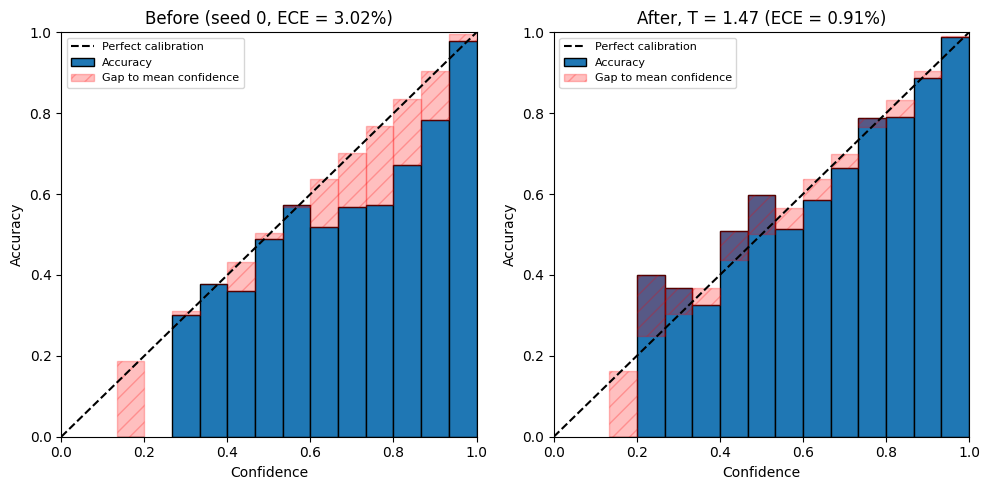

In [8]:
tl, ty = saved[SEEDS[0]]
t0 = temps[SEEDS[0]]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_reliability(tl, ty, f'Before (seed 0, ECE = {100*calibration_stats(tl, ty)[1]:.2f}%)', axes[0])
plot_reliability(tl / t0, ty, f'After, T = {t0:.2f} (ECE = {100*calibration_stats(tl / t0, ty)[1]:.2f}%)', axes[1])
plt.tight_layout()
plt.savefig(f'{FIG}/reliability_before_after.png', dpi=150)
plt.show()

**Reliability diagrams (seed 0).** Before scaling, the bars sit below the diagonal in the mid-confidence bins (the shaded gap is the overconfidence). After scaling, the bars follow the diagonal much more closely, especially in the top bin, which holds most of the images. A few low-confidence bins contain very few images, so their bars are noisy and contribute little to ECE.

## 7. Extension: calibration under distribution shift

The temperature $T$ is fitted on clean validation images. Test images are now corrupted at increasing strength, while the **same $T$ is applied unchanged**:

- **Gaussian noise:** add noise with standard deviation $s$ to pixel values in $[0,1]$, then clip back to $[0,1]$.
- **Gaussian blur:** blur with standard deviation $\sigma$ pixels (7x7 kernel).

The networks were not trained with noise or blur augmentation, so accuracy drops quickly. This is a simple, self-contained stand-in for the standard CIFAR-10-C benchmark, which has 19 corruption types at 5 severities. The results are cached in `shift_results_all_seeds.csv`; delete that file to recompute them (a couple of minutes on a GPU).

In [9]:
SHIFT_CSV = f'{PROJ}/shift_results_all_seeds.csv'
LEVELS = {'noise': [0, 0.01, 0.02, 0.03, 0.05, 0.1], 'blur': [0, 0.25, 0.5, 0.75, 1.0, 1.5]}

def corrupt(x, kind, level):
    if level == 0:
        return x
    if kind == 'noise':
        return (x + level * torch.randn_like(x)).clamp(0, 1)
    if kind == 'blur':
        return TF.gaussian_blur(x, kernel_size=7, sigma=level)

def run_shift_experiment():
    norm_mean = torch.tensor(NORM_MEAN).view(1, 3, 1, 1).to(device)
    norm_std = torch.tensor(NORM_STD).view(1, 3, 1, 1).to(device)
    raw_test = torchvision.datasets.CIFAR10(f'{PROJ}/data', train=False, download=True, transform=T.ToTensor())
    raw_loader = DataLoader(raw_test, batch_size=256)
    out_rows = []
    for s in SEEDS:
        d = torch.load(f'{PROJ}/logits_seed{s}.pt')
        t_s = fit_temperature(d['val_logits'], d['val_labels'])        # fitted on CLEAN validation data
        model = make_model()
        model.load_state_dict(torch.load(f'{PROJ}/resnet18_seed{s}.pt', map_location=device))
        model.eval()
        for kind, lvs in LEVELS.items():
            for level in lvs:
                torch.manual_seed(123)                                 # same noise draws on every run
                outs, ys = [], []
                with torch.no_grad():
                    for x, y in raw_loader:
                        x = corrupt(x.to(device), kind, level)
                        outs.append(model((x - norm_mean) / norm_std).cpu())
                        ys.append(y)
                logits, labels = torch.cat(outs), torch.cat(ys)
                for name, z in [('no scaling', logits), ('T scaled', logits / t_s)]:
                    acc, ece, mce, nll = calibration_stats(z, labels)
                    out_rows.append({'seed': s, 'corruption': kind, 'level': level, 'model': name,
                                     'accuracy %': 100 * acc, 'ECE %': 100 * ece, 'NLL': nll})
        print(f'seed {s} done')
    return pd.DataFrame(out_rows)

if os.path.exists(SHIFT_CSV):
    shift_all = pd.read_csv(SHIFT_CSV)
    print('loaded cached results from', SHIFT_CSV)
else:
    shift_all = run_shift_experiment()
    shift_all.to_csv(SHIFT_CSV, index=False)

acc_tbl = shift_all[shift_all.model == 'no scaling'].groupby(['corruption', 'level'])['accuracy %'].mean()
ece_tbl = shift_all.groupby(['corruption', 'level', 'model'])['ECE %'].mean().unstack('model')
compact = ece_tbl.join(acc_tbl).round(2)
display(compact)

loaded cached results from /content/drive/MyDrive/calib_project/shift_results_all_seeds.csv


T scaled  no scaling  accuracy %
corruption level                                  
blur       0.00       0.75        3.13       92.97
           0.25       0.77        3.11       92.99
           0.50       1.38        4.47       91.02
           0.75      14.77       21.81       65.12
           1.00      40.38       49.68       32.68
           1.50      56.85       66.16       18.90
noise      0.00       0.75        3.13       92.97
           0.01       0.73        3.54       92.26
           0.02       1.38        5.05       89.38
           0.03       3.70        8.32       84.05
           0.05      11.96       18.69       68.93
           0.10      48.19       56.44       27.99

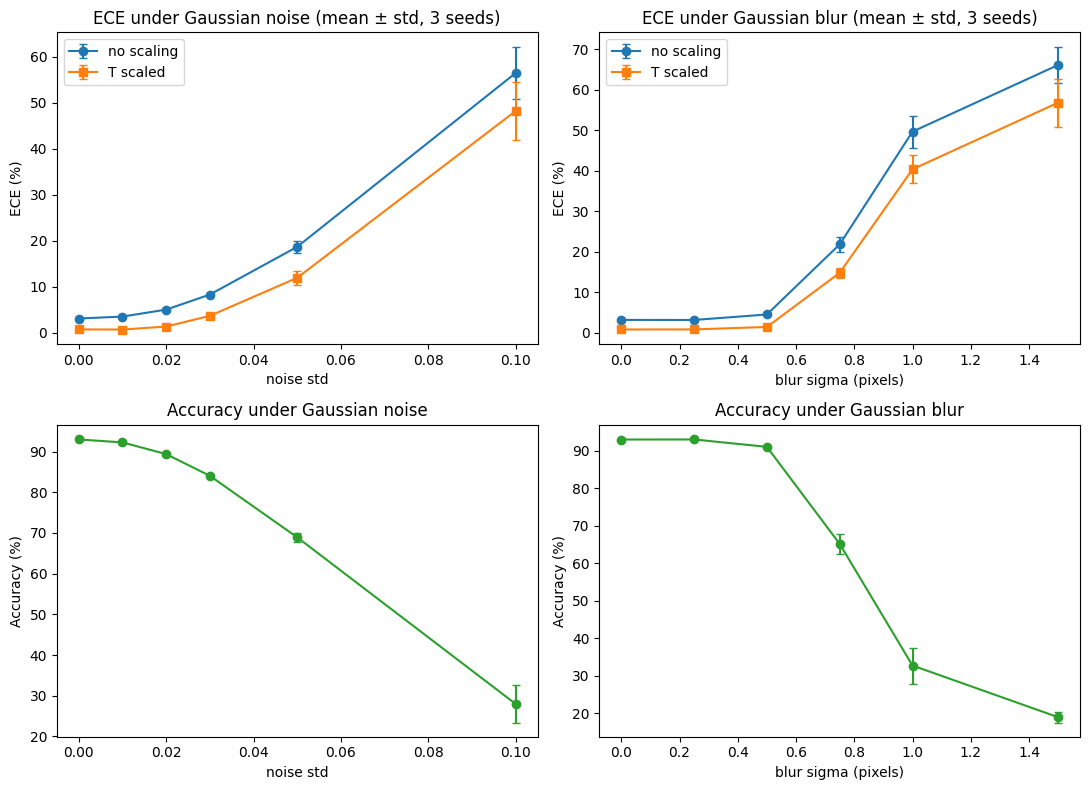

In [10]:
g = shift_all.groupby(['corruption', 'model', 'level'])[['accuracy %', 'ECE %']].agg(['mean', 'std'])

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for j, kind in enumerate(['noise', 'blur']):
    for name, style in [('no scaling', 'o-'), ('T scaled', 's-')]:
        sub = g.loc[(kind, name)]
        axes[0, j].errorbar(sub.index, sub[('ECE %', 'mean')], yerr=sub[('ECE %', 'std')],
                            fmt=style, capsize=3, label=name)
    sub = g.loc[(kind, 'no scaling')]
    axes[1, j].errorbar(sub.index, sub[('accuracy %', 'mean')], yerr=sub[('accuracy %', 'std')],
                        fmt='o-', capsize=3, color='tab:green')
    axes[0, j].set_title(f'ECE under Gaussian {kind} (mean ± std, 3 seeds)')
    axes[0, j].set_ylabel('ECE (%)'); axes[0, j].legend()
    axes[1, j].set_title(f'Accuracy under Gaussian {kind}')
    axes[1, j].set_ylabel('Accuracy (%)')
    for i in range(2):
        axes[i, j].set_xlabel('noise std' if kind == 'noise' else 'blur sigma (pixels)')
plt.tight_layout()
plt.savefig(f'{FIG}/calibration_under_shift_3seeds.png', dpi=150)
plt.show()

**Selected results** (mean over 3 seeds; ECE in %, from the table above):

| corruption | level | accuracy | ECE, no scaling | ECE, T scaled | relative reduction |
|---|---|---|---|---|---|
| none | 0 | 92.97 | 3.13 | 0.75 | 76 % |
| noise | 0.02 | 89.38 | 5.05 | 1.38 | 73 % |
| noise | 0.03 | 84.05 | 8.32 | 3.70 | 56 % |
| noise | 0.05 | 68.93 | 18.69 | 11.96 | 36 % |
| noise | 0.10 | 27.99 | 56.44 | 48.19 | 15 % |
| blur | 0.50 | 91.02 | 4.47 | 1.38 | 69 % |
| blur | 0.75 | 65.12 | 21.81 | 14.77 | 32 % |
| blur | 1.00 | 32.68 | 49.68 | 40.38 | 19 % |

**Findings.**

1. Accuracy and calibration both degrade quickly with corruption. Uncalibrated ECE grows from 3 % on clean images to 19 % at noise 0.05 and to over 50 % at the heaviest levels.
2. While the corruption is mild (noise up to 0.02 and blur up to 0.5, accuracy at or above about 89 %), temperature scaling keeps ECE between about 0.7 % and 1.4 %, roughly a three- to fivefold reduction.
3. As accuracy falls, the benefit shrinks: the relative reduction goes from over 70 % to about 15 to 20 % at the heaviest levels, and the scaled ECE remains large (12 % at noise 0.05, 40 % at blur 1.0).
4. At the heaviest levels the spread across seeds (standard deviations of roughly 3.5 to 6.5 points) is comparable to the gain from scaling, so only the qualitative statement "scaling helps little there" should be read from those rows.

A plausible reading is that the temperature is a global property of the network on in-distribution data, and the corrupted images produce errors that a single rescaling cannot absorb. This explanation was not tested here. The result agrees in direction with the study of calibration under dataset shift by Ovadia et al. (2019), which reports that calibration degrades under shift even for methods that look well calibrated in-distribution.

## 8. Comparison with the paper

Table 1 of Guo et al. reports ECE (%) with $M = 15$ bins for CIFAR-10 with a 45,000 / 5,000 / 10,000 train / validation / test split, the same protocol used here.

| model | uncalibrated ECE | temperature scaling ECE |
|---|---|---|
| ResNet 110 (paper) | 4.6 | 0.83 |
| ResNet 110, stochastic depth (paper) | 4.12 | 0.6 |
| Wide ResNet 32 (paper) | 4.52 | 0.54 |
| DenseNet 40 (paper) | 3.28 | 0.33 |
| **ResNet-18 (this notebook, 3 seeds)** | **3.13 ± 0.13** | **0.75 ± 0.14** |

The qualitative result reproduces: the uncalibrated network is overconfident with an ECE of a few percent, and temperature scaling reduces it to under 1 % without changing accuracy. The uncalibrated ECE here is in the range of the paper's values (closest to DenseNet 40). The scaled ECE (0.75 %) is of the same order as the paper's (0.33 to 0.83 %), though slightly higher than most of the paper's rows. The architecture and training recipe differ from the paper's models, so the exact numbers are not expected to match, and no claim is made about the cause of the remaining differences.

## 9. Limitations and next steps

**Limitations**

- One dataset (CIFAR-10) and one architecture (ResNet-18). The paper studies several datasets and models, and found that depth, width, weight decay and batch normalisation affect calibration.
- Only temperature scaling is implemented. The paper also compares histogram binning, isotonic regression, BBQ, matrix scaling and vector scaling.
- Three seeds give only rough estimates of the spread. The standard deviations are sample standard deviations over n = 3.
- The shift study uses two synthetic corruptions with a fixed kernel size, not the full CIFAR-10-C benchmark, and the networks were trained without any noise or blur augmentation.
- ECE depends on the number of bins and has known bias for small samples. MCE is too noisy at this sample size to support conclusions.
- The temperature grid has a resolution of 0.01.

**Possible next steps**

- Run the extension on the official CIFAR-10-C files.
- Add vector scaling or isotonic regression as baselines, and test whether they hold up better under shift.
- Compare a shallower and a deeper network, or training with and without weight decay, to test the paper's observations about the causes of miscalibration.
- Test label smoothing or a small ensemble as alternative remedies under shift.

## 10. Reproducibility and references

**To reproduce.** Open the notebook in Colab, set `TRAIN = True` and run all cells (about 20 to 25 minutes per seed on a free GPU, plus a couple of minutes for the extension). With `TRAIN = False` the notebook expects the saved files `resnet18_seed{0,1,2}.pt` and `logits_seed{0,1,2}.pt` in the Drive folder `calib_project`. Training uses fixed seeds, but GPU kernels are not bit-for-bit deterministic, so retrained models may differ slightly from those used for the numbers above.

**References**

1. C. Guo, G. Pleiss, Y. Sun, K. Q. Weinberger. *On Calibration of Modern Neural Networks.* ICML 2017. arXiv:1706.04599.
2. Y. Ovadia et al. *Can You Trust Your Model's Uncertainty? Evaluating Predictive Uncertainty Under Dataset Shift.* NeurIPS 2019.
3. K. He, X. Zhang, S. Ren, J. Sun. *Deep Residual Learning for Image Recognition.* CVPR 2016.
4. A. Krizhevsky. *Learning Multiple Layers of Features from Tiny Images* (CIFAR-10), 2009.